# RQ4 — Within-Corpus Benchmark

This notebook compares the six evaluated approaches on the same 30 projects under the within-corpus holdout protocol. Projects are the paired experimental units and approaches are the within-project conditions.

The automatic workflow follows the prespecified repeated-measures decision rule:

1. inspect Shapiro–Wilk normality for every approach;
2. if normality is not rejected for all approaches, use repeated-measures ANOVA, applying the Greenhouse–Geisser correction when Mauchly's test rejects sphericity;
3. otherwise, use the Friedman test;
4. run pairwise post-hoc tests only after a significant omnibus result;
5. use paired Student's $t$-tests with Hedges' $g$ on the parametric route, or Wilcoxon signed-rank tests with matched-pairs rank-biserial correlation ($r_{rb}$) on the non-parametric route;
6. adjust the complete family of pairwise $p$-values with Holm's procedure.

These inferential comparisons are valid only because the approaches in this file share the same projects, label space, inputs, and evaluation protocol. Scores obtained from other datasets or incompatible protocols must be reported separately rather than inserted as additional columns.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

try:
    import pingouin as pg
except ImportError as exc:
    raise ImportError(
        "This notebook requires 'pingouin'. Install the replication-package "
        "dependencies from requirements.txt before running the analysis."
    ) from exc

EXPECTED_PROJECTS = 30
EXPECTED_APPROACH_COLUMNS = [
    "gpt-oss",
    "codebert",
    "flaccs",
    "bilstm",
    "svm",
    "hqcm",
]

DISPLAY_LABELS = {
    "gpt-oss": "GPT-OSS 20B",
    "codebert": "CodeBERT",
    "flaccs": "FLACCS",
    "bilstm": "BiLSTM",
    "svm": "TF-IDF + Linear SVM",
    "hqcm": "CodeFuse HQCM",
}

# Support the two common execution locations:
# 1) the notebook directory itself; and
# 2) the repository root.
DATA_CANDIDATES = [
    Path("../metrics/benchmark_macro_f1.csv"),
    Path("results/rq4_1/within_corpus/metrics/benchmark_macro_f1.csv"),
    Path("metrics/benchmark_macro_f1.csv"),
]

DATA_PATH = next(
    (candidate.resolve() for candidate in DATA_CANDIDATES if candidate.exists()),
    None,
)
if DATA_PATH is None:
    tried = "\n".join(f"  - {path}" for path in DATA_CANDIDATES)
    raise FileNotFoundError(
        "Could not locate the within-corpus benchmark CSV. Tried:\n" + tried
    )

df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()

expected_columns = ["project", *EXPECTED_APPROACH_COLUMNS]
missing_columns = [column for column in expected_columns if column not in df_raw.columns]
extra_columns = [column for column in df_raw.columns if column not in expected_columns]
if missing_columns or extra_columns:
    raise ValueError(
        "Unexpected benchmark schema. "
        f"Missing={missing_columns}; extra={extra_columns}"
    )

if len(df_raw) != EXPECTED_PROJECTS:
    raise ValueError(
        f"Expected {EXPECTED_PROJECTS} project rows, found {len(df_raw)}."
    )

if df_raw["project"].isna().any():
    raise ValueError("Project identifiers must not be missing.")

if df_raw["project"].duplicated().any():
    duplicates = df_raw.loc[
        df_raw["project"].duplicated(),
        "project",
    ].astype(str).tolist()
    raise ValueError(
        f"Duplicate project identifiers were found: {duplicates}"
    )

for column in EXPECTED_APPROACH_COLUMNS:
    df_raw[column] = pd.to_numeric(df_raw[column], errors="raise")

if df_raw[EXPECTED_APPROACH_COLUMNS].isna().any().any():
    missing = df_raw[EXPECTED_APPROACH_COLUMNS].isna().sum()
    missing = missing[missing > 0].to_dict()
    raise ValueError(f"Benchmark contains missing Macro-F1 values: {missing}")

invalid_mask = (
    (df_raw[EXPECTED_APPROACH_COLUMNS] < 0)
    | (df_raw[EXPECTED_APPROACH_COLUMNS] > 1)
)
if invalid_mask.any().any():
    raise ValueError("Benchmark Macro-F1 values must lie in the [0, 1] interval.")

# Keep the frozen approach order from the benchmark definition.
df_clean = (
    df_raw.set_index("project")[EXPECTED_APPROACH_COLUMNS]
    .rename(columns=DISPLAY_LABELS)
    .copy()
)

print(f"Data file: {DATA_PATH}")
print(f"Complete paired projects: {len(df_clean)}")
print(f"Benchmark approaches ({len(df_clean.columns)}): {df_clean.columns.tolist()}")

display(df_clean.head())


Data file: D:\sources\next.release.number\results\rq4_1\within_corpus\metrics\benchmark_macro_f1.csv
Complete paired projects: 30
Benchmark approaches (6): ['GPT-OSS 20B', 'CodeBERT', 'FLACCS', 'BiLSTM', 'TF-IDF + Linear SVM', 'CodeFuse HQCM']


,GPT-OSS 20B,CodeBERT,FLACCS,BiLSTM,TF-IDF + Linear SVM,CodeFuse HQCM
project,,,,,,
angular,0.400705,0.664170,0.448144,0.590194,0.506429,0.180000
ant-design,0.493764,0.704543,0.336930,0.626326,0.533766,0.193395
biome,0.520181,0.468211,0.468274,0.462280,0.411800,0.119048
bun,0.566036,0.596101,0.455556,0.507835,0.548840,0.111111
clap,0.538139,0.576326,0.693497,0.675147,0.463371,0.258838


## Automatic repeated-measures analysis

The compact benchmark table reports mean project Macro-F1, standard deviation, an unadjusted 95% confidence interval, and mean rank. Lower mean ranks indicate better within-project performance.

When post-hoc comparisons are warranted, “not significantly different from the leading approach” is not an equivalence claim. Results from this within-corpus protocol must not be pooled with scores from cross-project benchmarks, original related-work datasets, or different class subsets.


In [2]:
import textwrap
from itertools import combinations
from scipy.stats import friedmanchisquare, shapiro, t, ttest_rel


def _format_decimal(value, digits=3):
    text = f"{float(value):.{digits}f}"
    if text.startswith("0."):
        return text[1:]
    if text.startswith("-0."):
        return "-" + text[2:]
    return text


def _format_p_markdown(p_value):
    p_value = float(p_value)
    if p_value < 0.001:
        return r"$p<.001$"
    return f"$p={_format_decimal(p_value)}$"


def _format_p_plain(p_value, digits=4):
    p_value = float(p_value)
    if p_value < 0.001:
        return "<.001"
    return f"{p_value:.{digits}f}".lstrip("0")


def _effect_magnitude(effect, route):
    value = abs(float(effect))

    if route == "parametric":
        if value < 0.2:
            return "Negligible"
        if value < 0.5:
            return "Small"
        if value < 0.8:
            return "Medium"
        return "Large"

    if value < 0.1:
        return "Negligible"
    if value < 0.3:
        return "Small"
    if value < 0.5:
        return "Medium"
    return "Large"


def _sphericity_values(result):
    """Support named and tuple-like Pingouin return objects."""
    names = ("spher", "W", "chi2", "dof", "pval")
    if all(hasattr(result, name) for name in names):
        return {name: getattr(result, name) for name in names}

    return dict(zip(names, result))


def _pingouin_value(row, *candidates):
    normalized = {
        str(column).lower().replace("-", "_"): column
        for column in row.index
    }
    for candidate in candidates:
        key = candidate.lower().replace("-", "_")
        if key in normalized:
            return row[normalized[key]]
    raise KeyError(
        f"None of these columns were found: {candidates}"
    )


def _descriptive_table(data):
    n = len(data)
    means = data.mean()
    standard_deviations = data.std(ddof=1)
    standard_errors = standard_deviations / np.sqrt(n)
    critical_t = t.ppf(0.975, df=n - 1)
    mean_ranks = data.rank(
        axis=1,
        method="average",
        ascending=False,
    ).mean()

    table = pd.DataFrame({
        "N": n,
        "Mean Macro-F1": means,
        "SD": standard_deviations,
        "CI95 Lower": means - critical_t * standard_errors,
        "CI95 Upper": means + critical_t * standard_errors,
        "Mean Rank": mean_ranks,
    })

    return table.sort_values(
        ["Mean Rank", "Mean Macro-F1"],
        ascending=[True, False],
    )


def _pairwise_tests(data, route, alpha):
    rows = []

    for model_a, model_b in combinations(data.columns, 2):
        values_a = data[model_a].to_numpy()
        values_b = data[model_b].to_numpy()

        if route == "parametric":
            statistic, p_value = ttest_rel(values_a, values_b)

            if np.allclose(values_a - values_b, 0):
                effect = 0.0
            else:
                effect = pg.compute_effsize(
                    values_a,
                    values_b,
                    paired=True,
                    eftype="hedges",
                )

            statistic_name = "t"
            effect_name = "Hedges' g"
        else:
            if np.allclose(values_a - values_b, 0):
                statistic = 0.0
                p_value = 1.0
                effect = 0.0
            else:
                wilcoxon = pg.wilcoxon(
                    values_a,
                    values_b,
                    alternative="two-sided",
                ).iloc[0]
                statistic = _pingouin_value(
                    wilcoxon,
                    "W_val",
                    "W-val",
                )
                p_value = _pingouin_value(
                    wilcoxon,
                    "p_val",
                    "p-val",
                )
                effect = _pingouin_value(wilcoxon, "RBC")

            statistic_name = "W"
            effect_name = "Rank-biserial correlation"

        rows.append({
            "A": model_a,
            "B": model_b,
            "Mean A": float(np.mean(values_a)),
            "Mean B": float(np.mean(values_b)),
            "Statistic name": statistic_name,
            "Statistic": float(statistic),
            "p_raw": float(p_value),
            "Effect name": effect_name,
            "Effect": float(effect),
        })

    pairwise = pd.DataFrame(rows)
    reject, corrected_p = pg.multicomp(
        pairwise["p_raw"].to_numpy(),
        alpha=alpha,
        method="holm",
    )
    pairwise["p_Holm"] = corrected_p
    pairwise["Significant"] = reject
    pairwise["Winner"] = np.where(
        pairwise["Effect"] >= 0,
        pairwise["A"],
        pairwise["B"],
    )
    pairwise["Loser"] = np.where(
        pairwise["Effect"] >= 0,
        pairwise["B"],
        pairwise["A"],
    )
    pairwise["Absolute effect"] = pairwise["Effect"].abs()
    pairwise["Effect magnitude"] = pairwise["Effect"].map(
        lambda value: _effect_magnitude(value, route)
    )

    return pairwise


def run_model_comparison(data, alpha=0.05):
    descriptive = _descriptive_table(data)

    shapiro_rows = []
    for model in data.columns:
        statistic, p_value = shapiro(data[model])
        shapiro_rows.append({
            "Model": model,
            "N": int(data[model].notna().sum()),
            "W": float(statistic),
            "p": float(p_value),
            "Normality not rejected": bool(p_value >= alpha),
        })

    shapiro_results = pd.DataFrame(shapiro_rows).set_index("Model")
    all_normal = bool(
        shapiro_results["Normality not rejected"].all()
    )
    route = "parametric" if all_normal else "non-parametric"

    n_projects = len(data)
    n_models = len(data.columns)
    sphericity = None

    if route == "parametric":
        long_data = (
            data.rename_axis("Project")
            .reset_index()
            .melt(
                id_vars="Project",
                var_name="Model",
                value_name="Macro-F1",
            )
        )

        sphericity = _sphericity_values(
            pg.sphericity(
                data=long_data,
                dv="Macro-F1",
                within="Model",
                subject="Project",
            )
        )

        anova = pg.rm_anova(
            data=long_data,
            dv="Macro-F1",
            within="Model",
            subject="Project",
            correction=True,
            detailed=True,
            effsize="ng2",
        )
        anova_row = anova.iloc[0]
        statistic = float(_pingouin_value(anova_row, "F"))
        p_uncorrected = float(
            _pingouin_value(anova_row, "p_unc", "p-unc")
        )
        epsilon = float(_pingouin_value(anova_row, "eps"))
        effect = float(_pingouin_value(anova_row, "ng2"))

        if float(sphericity["pval"]) < alpha:
            p_value = float(
                _pingouin_value(
                    anova_row,
                    "p_GG_corr",
                    "p-GG-corr",
                )
            )
            df1 = epsilon * (n_models - 1)
            df2 = epsilon * (n_models - 1) * (n_projects - 1)
            correction = "Greenhouse-Geisser"
        else:
            p_value = p_uncorrected
            df1 = n_models - 1
            df2 = (n_models - 1) * (n_projects - 1)
            correction = "None"

        omnibus = {
            "test": "Repeated-measures ANOVA",
            "statistic name": "F",
            "statistic": statistic,
            "df1": float(df1),
            "df2": float(df2),
            "p": p_value,
            "effect name": "eta_G_squared",
            "effect": effect,
            "epsilon": epsilon,
            "correction": correction,
            "significant": bool(p_value < alpha),
        }
    else:
        statistic, p_value = friedmanchisquare(
            *[data[column].to_numpy() for column in data.columns]
        )
        kendalls_w = statistic / (
            n_projects * (n_models - 1)
        )
        omnibus = {
            "test": "Friedman",
            "statistic name": "chi-square",
            "statistic": float(statistic),
            "df1": float(n_models - 1),
            "df2": np.nan,
            "p": float(p_value),
            "effect name": "Kendall's W",
            "effect": float(kendalls_w),
            "epsilon": np.nan,
            "correction": "Not applicable",
            "significant": bool(p_value < alpha),
        }

    if omnibus["significant"]:
        pairwise = _pairwise_tests(data, route, alpha)
        significant_pairwise = pairwise.loc[
            pairwise["Significant"]
        ].copy()
    else:
        pairwise = None
        significant_pairwise = None

    leader = descriptive.index[0]
    not_distinguishable = [leader]

    if pairwise is not None:
        for model in descriptive.index[1:]:
            comparison = pairwise.loc[
                (
                    (pairwise["A"] == leader)
                    & (pairwise["B"] == model)
                )
                | (
                    (pairwise["A"] == model)
                    & (pairwise["B"] == leader)
                )
            ]
            if len(comparison) != 1:
                raise ValueError(
                    "Missing or duplicated leader comparison for "
                    f"{model}."
                )
            if not bool(comparison.iloc[0]["Significant"]):
                not_distinguishable.append(model)

    summary = descriptive.copy()
    if pairwise is None:
        summary["Not significantly different from leader"] = pd.NA
    else:
        summary["Not significantly different from leader"] = [
            model in not_distinguishable
            for model in summary.index
        ]

    print("DESCRIPTIVE APPROACH TABLE")
    display(summary.round({
        "Mean Macro-F1": 4,
        "SD": 4,
        "CI95 Lower": 4,
        "CI95 Upper": 4,
        "Mean Rank": 2,
    }))

    print("SHAPIRO-WILK TESTS")
    shapiro_display = shapiro_results.copy()
    shapiro_display["W"] = shapiro_display["W"].round(4)
    shapiro_display["p"] = shapiro_display["p"].map(
        _format_p_plain
    )
    display(shapiro_display)

    print(f"SELECTED ROUTE: {route}")
    display(pd.DataFrame([omnibus]))

    if pairwise is None:
        print(
            "The omnibus test was not significant; confirmatory "
            "post-hoc comparisons were not performed."
        )
    else:
        print(
            "SIGNIFICANT HOLM-CORRECTED PAIRWISE COMPARISONS "
            f"({len(significant_pairwise)} of {len(pairwise)})"
        )
        pairwise_display = significant_pairwise.copy()
        pairwise_display["p_raw"] = pairwise_display["p_raw"].map(
            _format_p_plain
        )
        pairwise_display["p_Holm"] = pairwise_display[
            "p_Holm"
        ].map(_format_p_plain)
        display(pairwise_display.round({
            "Mean A": 4,
            "Mean B": 4,
            "Statistic": 4,
            "Effect": 4,
        }))

    return {
        "data": data,
        "descriptive": descriptive,
        "summary": summary,
        "shapiro": shapiro_results,
        "route": route,
        "sphericity": sphericity,
        "omnibus": omnibus,
        "pairwise": pairwise,
        "significant_pairwise": significant_pairwise,
        "leader": leader,
        "not_distinguishable": not_distinguishable,
        "alpha": alpha,
    }


def generate_model_comparison_report(
    analysis,
    title="RQ4 within-corpus benchmark interpretation generated from current data",
):
    route = analysis["route"]
    shapiro_results = analysis["shapiro"]
    omnibus = analysis["omnibus"]
    significant = analysis["significant_pairwise"]
    pairwise = analysis["pairwise"]
    leader = analysis["leader"]
    descriptive = analysis["descriptive"]
    not_distinguishable = analysis["not_distinguishable"]

    if route == "non-parametric":
        failed_models = shapiro_results.index[
            ~shapiro_results["Normality not rejected"]
        ].tolist()
        assumption_text = (
            "Shapiro–Wilk rejected normality for at least one model "
            "(" + ", ".join(failed_models) + "). The non-parametric "
            "repeated-measures route was therefore selected."
        )
        omnibus_text = (
            "The Friedman test "
            + ("detected" if omnibus["significant"] else "did not detect")
            + " an overall approach effect, "
            + f"$\\chi^2({int(omnibus['df1'])})="
            + f"{omnibus['statistic']:.2f}$, "
            + f"{_format_p_markdown(omnibus['p'])}, "
            + f"Kendall's $W={_format_decimal(omnibus['effect'])}$."
        )
        posthoc_name = (
            "Wilcoxon signed-rank tests with Holm correction and "
            "matched-pairs rank-biserial correlations"
        )
    else:
        assumption_text = (
            "Shapiro–Wilk did not reject normality for any approach, "
            "so the parametric repeated-measures route was selected."
        )
        sphericity = analysis["sphericity"]
        if float(sphericity["pval"]) < analysis["alpha"]:
            assumption_text += (
                " Mauchly's test rejected sphericity "
                f"($W={_format_decimal(sphericity['W'])}$, "
                f"{_format_p_markdown(sphericity['pval'])}); the "
                "Greenhouse–Geisser correction was applied."
            )
        else:
            assumption_text += (
                " Mauchly's test did not reject sphericity "
                f"($W={_format_decimal(sphericity['W'])}$, "
                f"{_format_p_markdown(sphericity['pval'])})."
            )

        omnibus_text = (
            "The repeated-measures ANOVA "
            + ("detected" if omnibus["significant"] else "did not detect")
            + " an overall approach effect, "
            + f"$F({omnibus['df1']:.2f},{omnibus['df2']:.2f})="
            + f"{omnibus['statistic']:.2f}$, "
            + f"{_format_p_markdown(omnibus['p'])}, "
            + f"$\\eta_G^2={_format_decimal(omnibus['effect'])}$."
        )
        posthoc_name = (
            "paired Student's $t$-tests with Holm correction and "
            "Hedges' $g$ effect sizes"
        )

    leader_mean = descriptive.loc[leader, "Mean Macro-F1"]
    leader_rank = descriptive.loc[leader, "Mean Rank"]

    if pairwise is None:
        pairwise_text = (
            "Because the omnibus result was not significant, "
            "confirmatory pairwise comparisons were not performed."
        )
    else:
        pairwise_text = (
            f"Post-hoc analysis used {posthoc_name}. "
            f"{len(significant)} of {len(pairwise)} pairwise "
            "comparisons remained significant after correction."
        )

    other_leaders = [
        model for model in not_distinguishable if model != leader
    ]
    if pairwise is None:
        leader_text = (
            f"**{leader}** had the lowest mean rank "
            f"({leader_rank:.2f}) and a mean Macro-F1 of "
            f"{leader_mean:.3f}. No confirmatory claim relative to "
            "the other approaches is made because the omnibus test "
            "was not significant."
        )
    elif other_leaders:
        leader_text = (
            f"**{leader}** had the lowest mean rank "
            f"({leader_rank:.2f}) and the highest corresponding "
            f"descriptive mean Macro-F1 ({leader_mean:.3f}). It was "
            "not statistically distinguishable from: "
            + ", ".join(f"**{model}**" for model in other_leaders)
            + ". This non-significant result does not demonstrate "
            "equivalence."
        )
    else:
        leader_text = (
            f"**{leader}** had the lowest mean rank "
            f"({leader_rank:.2f}) and a mean Macro-F1 of "
            f"{leader_mean:.3f}; it differed significantly from "
            "every other evaluated model."
        )

    if omnibus["significant"]:
        conclusion = (
            "The evaluated approaches did not perform uniformly across "
            "projects. The complete descriptive table should be used "
            "to report all models, while corrected pairwise results "
            "support only the specific statistical distinctions "
            "identified by the post-hoc analysis."
        )
    else:
        conclusion = (
            "The observed model ordering is descriptive because the "
            "omnibus test did not detect an overall difference."
        )

    report = f"""
## {title}

### Assumptions and omnibus test

{assumption_text} {omnibus_text}

### Descriptive ranking and pairwise evidence

{leader_text} {pairwise_text}

### Data-driven interpretation

{conclusion}
"""
    return textwrap.dedent(report)


## Execute the benchmark analysis

Every table and interpretive sentence below is regenerated from the current benchmark CSV. Post-hoc comparisons are conditional on the omnibus result.


In [3]:
benchmark_analysis = run_model_comparison(df_clean)
benchmark_report = generate_model_comparison_report(
    benchmark_analysis
)
display(Markdown(benchmark_report))


DESCRIPTIVE APPROACH TABLE


,N,Mean Macro-F1,SD,CI95 Lower,CI95 Upper,Mean Rank,Not significantly different from leader
CodeBERT,30,0.5828,0.1469,0.5280,0.6377,1.87,True
BiLSTM,30,0.5166,0.1068,0.4768,0.5565,2.90,False
TF-IDF + Linear SVM,30,0.4986,0.1226,0.4528,0.5444,3.07,False
GPT-OSS 20B,30,0.4890,0.1434,0.4355,0.5425,3.07,False
FLACCS,30,0.4193,0.1065,0.3795,0.4591,4.10,False
CodeFuse HQCM,30,0.1797,0.0815,0.1493,0.2102,6.00,False


SHAPIRO-WILK TESTS


,N,W,p,Normality not rejected
Model,,,,
GPT-OSS 20B,30,0.9670,.4596,True
CodeBERT,30,0.9498,.1667,True
FLACCS,30,0.9676,.4762,True
BiLSTM,30,0.9713,.5750,True
TF-IDF + Linear SVM,30,0.9697,.5321,True
CodeFuse HQCM,30,0.9444,.1194,True


SELECTED ROUTE: parametric


,test,statistic name,statistic,df1,df2,p,effect name,effect,epsilon,correction,significant
0,Repeated-measures ANOVA,F,71.777329,3.515162,101.93971,4.496582e-27,eta_G_squared,0.544249,0.703032,Greenhouse-Geisser,True


SIGNIFICANT HOLM-CORRECTED PAIRWISE COMPARISONS (12 of 15)


,A,B,Mean A,Mean B,Statistic name,Statistic,p_raw,Effect name,Effect,p_Holm,Significant,Winner,Loser,Absolute effect,Effect magnitude
0,GPT-OSS 20B,CodeBERT,0.4890,0.5828,t,-3.3599,.0022,Hedges' g,-0.6379,.0132,True,CodeBERT,GPT-OSS 20B,0.637933,Medium
1,GPT-OSS 20B,FLACCS,0.4890,0.4193,t,3.4282,.0018,Hedges' g,0.5444,.0129,True,GPT-OSS 20B,FLACCS,0.544406,Medium
4,GPT-OSS 20B,CodeFuse HQCM,0.4890,0.1797,t,13.0321,<.001,Hedges' g,2.6177,<.001,True,GPT-OSS 20B,CodeFuse HQCM,2.617695,Large
5,CodeBERT,FLACCS,0.5828,0.4193,t,6.1878,<.001,Hedges' g,1.2574,<.001,True,CodeBERT,FLACCS,1.257429,Large
6,CodeBERT,BiLSTM,0.5828,0.5166,t,3.2576,.0029,Hedges' g,0.5088,.0143,True,CodeBERT,BiLSTM,0.508811,Medium
7,CodeBERT,TF-IDF + Linear SVM,0.5828,0.4986,t,3.9907,<.001,Hedges' g,0.6144,.0033,True,CodeBERT,TF-IDF + Linear SVM,0.614374,Medium
8,CodeBERT,CodeFuse HQCM,0.5828,0.1797,t,16.0949,<.001,Hedges' g,3.3490,<.001,True,CodeBERT,CodeFuse HQCM,3.348969,Large
9,FLACCS,BiLSTM,0.4193,0.5166,t,-4.6135,<.001,Hedges' g,-0.9004,<.001,True,BiLSTM,FLACCS,0.900434,Large
10,FLACCS,TF-IDF + Linear SVM,0.4193,0.4986,t,-2.8681,.0076,Hedges' g,-0.6814,.0305,True,TF-IDF + Linear SVM,FLACCS,0.681382,Medium
11,FLACCS,CodeFuse HQCM,0.4193,0.1797,t,12.2557,<.001,Hedges' g,2.4936,<.001,True,FLACCS,CodeFuse HQCM,2.493624,Large



## RQ4 within-corpus benchmark interpretation generated from current data

### Assumptions and omnibus test

Shapiro–Wilk did not reject normality for any approach, so the parametric repeated-measures route was selected. Mauchly's test rejected sphericity ($W=.376$, $p=.023$); the Greenhouse–Geisser correction was applied. The repeated-measures ANOVA detected an overall approach effect, $F(3.52,101.94)=71.78$, $p<.001$, $\eta_G^2=.544$.

### Descriptive ranking and pairwise evidence

**CodeBERT** had the lowest mean rank (1.87) and a mean Macro-F1 of 0.583; it differed significantly from every other evaluated model. Post-hoc analysis used paired Student's $t$-tests with Holm correction and Hedges' $g$ effect sizes. 12 of 15 pairwise comparisons remained significant after correction.

### Data-driven interpretation

The evaluated approaches did not perform uniformly across projects. The complete descriptive table should be used to report all models, while corrected pairwise results support only the specific statistical distinctions identified by the post-hoc analysis.


## Compact benchmark table

This table is the main descriptive answer for this within-corpus benchmark. Dataset, class set, project count, and split protocol should be identified in the article caption or adjacent text.


In [4]:
article_table = benchmark_analysis["summary"][[
    "Mean Macro-F1",
    "SD",
    "Mean Rank",
    "Not significantly different from leader",
]].copy()

display(article_table.round({
    "Mean Macro-F1": 3,
    "SD": 3,
    "Mean Rank": 2,
}))


,Mean Macro-F1,SD,Mean Rank,Not significantly different from leader
CodeBERT,0.583,0.147,1.87,True
BiLSTM,0.517,0.107,2.90,False
TF-IDF + Linear SVM,0.499,0.123,3.07,False
GPT-OSS 20B,0.489,0.143,3.07,False
FLACCS,0.419,0.107,4.10,False
CodeFuse HQCM,0.180,0.081,6.00,False


## Holm-corrected pairwise effect-size heatmap

This additional visualization contains only statistically significant pairwise comparisons. The compact benchmark table remains the main result; the complete pairwise output is exported as CSV.


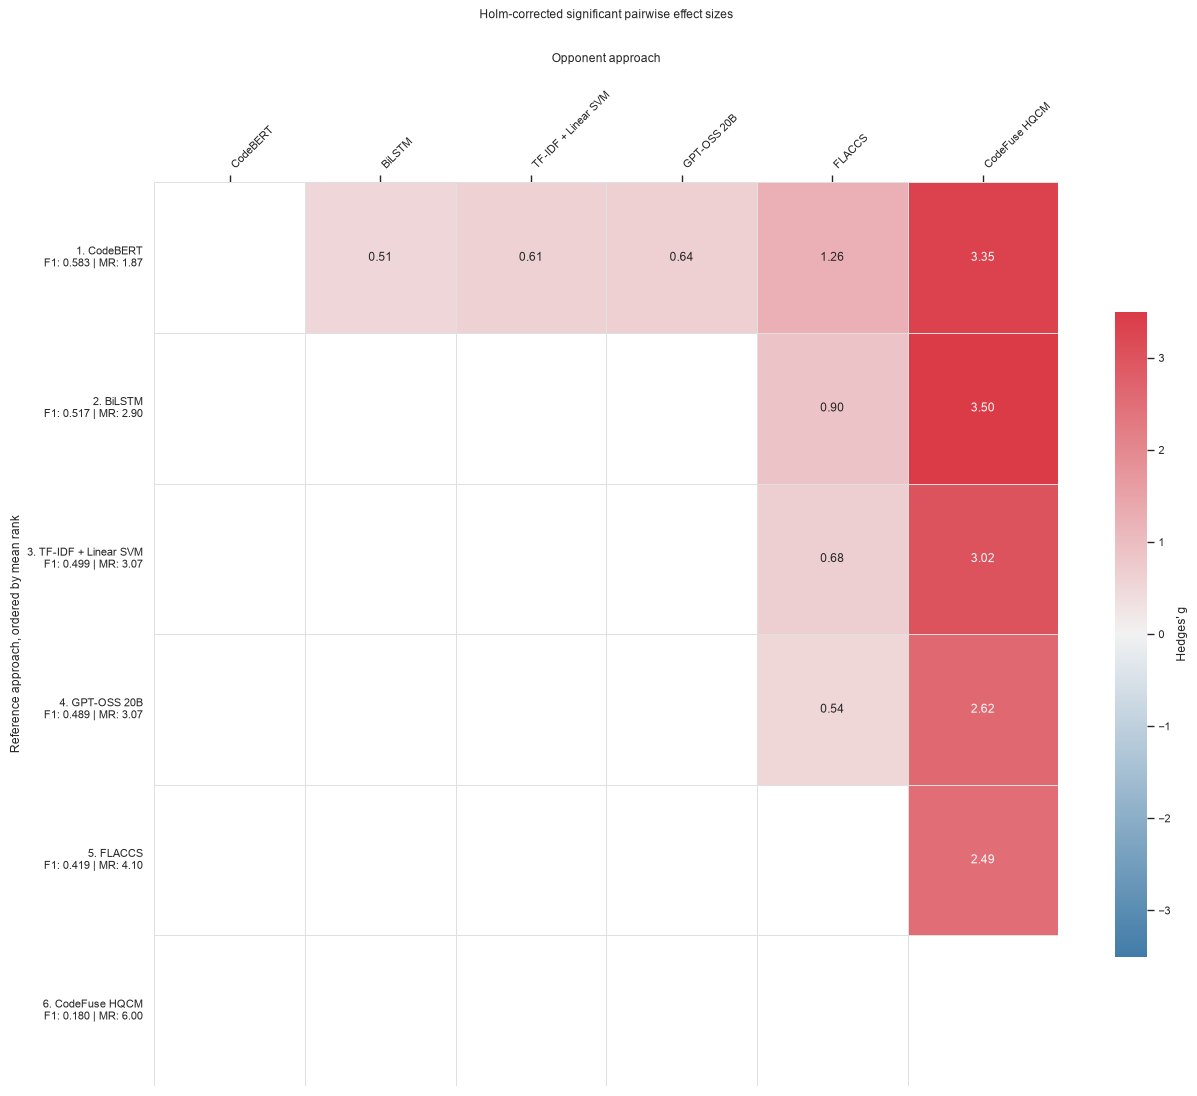

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

pairwise = benchmark_analysis["pairwise"]

if pairwise is None:
    print(
        "Heatmap not generated because confirmatory post-hoc tests "
        "were not warranted."
    )
else:
    ordered_models = benchmark_analysis["descriptive"].index.tolist()
    effect_matrix = pd.DataFrame(
        np.nan,
        index=ordered_models,
        columns=ordered_models,
    )
    p_matrix = effect_matrix.copy()

    for _, row in pairwise.iterrows():
        model_a = row["A"]
        model_b = row["B"]
        effect = row["Effect"]
        p_value = row["p_Holm"]

        effect_matrix.loc[model_a, model_b] = effect
        effect_matrix.loc[model_b, model_a] = -effect
        p_matrix.loc[model_a, model_b] = p_value
        p_matrix.loc[model_b, model_a] = p_value

    display_matrix = effect_matrix.copy()
    annotations = pd.DataFrame(
        "",
        index=ordered_models,
        columns=ordered_models,
    )

    for row_index in range(len(ordered_models)):
        for column_index in range(len(ordered_models)):
            p_value = p_matrix.iloc[row_index, column_index]
            value = effect_matrix.iloc[row_index, column_index]

            if (
                column_index > row_index
                and pd.notna(p_value)
                and p_value < benchmark_analysis["alpha"]
            ):
                annotations.iloc[
                    row_index,
                    column_index,
                ] = f"{value:.2f}"
            else:
                display_matrix.iloc[
                    row_index,
                    column_index,
                ] = np.nan

    diagonal_and_lower = np.tril(
        np.ones(display_matrix.shape, dtype=bool),
        k=0,
    )

    row_labels = []
    for position, model in enumerate(ordered_models, start=1):
        row = benchmark_analysis["descriptive"].loc[model]
        row_labels.append(
            f"{position}. {model}\n"
            f"F1: {row['Mean Macro-F1']:.3f} | "
            f"MR: {row['Mean Rank']:.2f}"
        )

    sns.set_theme(style="white", context="paper", font_scale=0.9)
    figure_size = max(11, 0.9 * len(ordered_models))
    fig, ax = plt.subplots(
        figsize=(figure_size + 2, figure_size),
    )

    color_map = sns.diverging_palette(240, 10, as_cmap=True)
    effect_label = (
        "Hedges' g"
        if benchmark_analysis["route"] == "parametric"
        else r"Rank-biserial correlation ($r_{rb}$)"
    )
    effect_limit = (
        max(1.0, float(pairwise["Effect"].abs().max()))
        if benchmark_analysis["route"] == "parametric"
        else 1.0
    )

    sns.heatmap(
        display_matrix,
        annot=annotations,
        fmt="",
        mask=diagonal_and_lower,
        cmap=color_map,
        center=0,
        vmin=-effect_limit,
        vmax=effect_limit,
        square=True,
        linewidths=0.6,
        linecolor="#e0e0e0",
        cbar_kws={"label": effect_label, "shrink": 0.7},
        ax=ax,
    )

    ax.set_xticklabels(
        ordered_models,
        rotation=45,
        ha="left",
    )
    ax.set_yticklabels(row_labels, rotation=0)
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel("Opponent approach", labelpad=20)
    ax.set_ylabel("Reference approach, ordered by mean rank")
    ax.set_title(
        "Holm-corrected significant pairwise effect sizes",
        pad=25,
    )

    fig.tight_layout()
    plt.show()


## Reproducibility notes

- Projects are the paired units and the frozen input must contain exactly the 30 expected projects and all six approaches.
- The input is loaded locally from `../metrics/benchmark_macro_f1.csv` when the notebook is run from `analysis/`, with a repository-root fallback for convenience.
- The route between repeated-measures ANOVA and Friedman is regenerated if the data change.
- Mauchly's test and Greenhouse–Geisser correction are used only on the parametric route.
- Confirmatory post-hoc tests are run only after a significant omnibus result.
- Holm correction covers all $k(k-1)/2$ approach pairs.
- Hedges' $g$ is used for paired parametric comparisons; $r_{rb}$ is used for Wilcoxon comparisons.
- Generated tables and the optional heatmap are displayed inline above and can be regenerated at any time by re-running the notebook; the frozen input remains under `metrics/` and nothing is written back to `results/`.
- Results from incompatible datasets, label spaces, or split protocols must be reported as separate benchmark scenarios.
